# 2 · 統計方法壓縮:PCA / t-SNE / Isomap

把 NB1 的建築表格向量(高維)壓到 2D 看結構。三種統計降維,各有脾氣:

- **PCA**:線性、封閉解、**軸可解釋**(主成分=特徵線性組合)、保全局方差。
- **t-SNE**:非線性、重局部鄰域、簇緊但**全局距離無意義**、隨機性大。
- **Isomap**:非線性、測地流形距離、保全局結構。

重點:**解釋性 vs 視覺分群**的取捨。

## 環境 + 資料

In [1]:
import sys, os
from pathlib import Path
_here = Path(os.getcwd()).resolve()
_r07 = next((p for p in [_here, *_here.parents] if (p / 'nn').exists()), _here)
if str(_r07) not in sys.path: sys.path.insert(0, str(_r07))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import nn                       # 建築層 + 中文字型自動修好
print('07 根:', _r07)

07 根: C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban


In [2]:
SLUG = 'lujiazui'
X, feat_names, aux = nn.make_dataset(SLUG)
print('X =', X.shape)
color_h = np.asarray(aux['height_m'], dtype=float)  # 用高度著色

X = (3263, 16)


## PCA:方差解釋 + 可解釋軸
看前 k 軸累積解釋多少方差(scree),以及每軸由哪些特徵組成(載荷)。

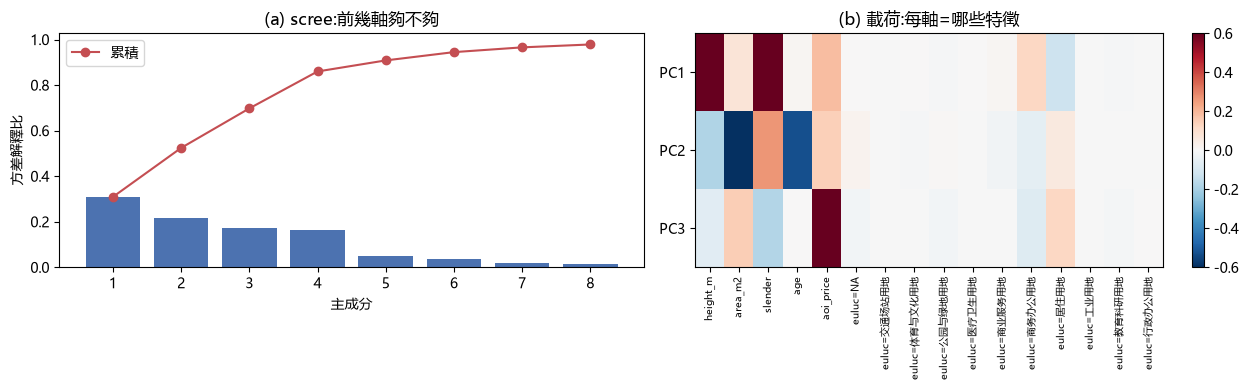

前2軸累積方差 52.4%


In [3]:
pca = nn.PCA(n_components=min(8, X.shape[1])).fit(X)
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, len(ev)+1), ev, color='#4c72b0')
ax[0].plot(range(1, len(ev)+1), np.cumsum(ev), 'o-', color='#c44e52', label='累積')
ax[0].set_xlabel('主成分'); ax[0].set_ylabel('方差解釋比'); ax[0].legend()
ax[0].set_title('(a) scree:前幾軸夠不夠')
L = pca.components_[:3]
im = ax[1].imshow(L, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
ax[1].set_yticks(range(3)); ax[1].set_yticklabels([f'PC{i+1}' for i in range(3)])
ax[1].set_xticks(range(len(feat_names))); ax[1].set_xticklabels(feat_names, rotation=90, fontsize=7)
ax[1].set_title('(b) 載荷:每軸=哪些特徵'); fig.colorbar(im, ax=ax[1])
fig.tight_layout(); plt.show()
print('前2軸累積方差 %.1f%%' % (ev[:2].sum()*100))

## 三方法 2D 投影同台
t-SNE / Isomap 沒有可解釋軸,只給座標。用高度著色看誰把高樓群分得清楚。

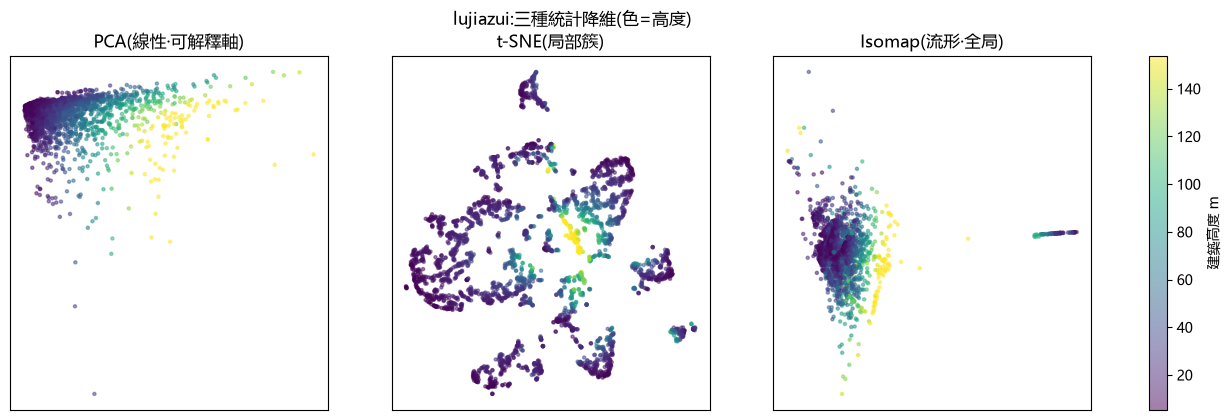

In [4]:
from sklearn.manifold import TSNE, Isomap
Zp = pca.transform(X)[:, :2]
Zt = TSNE(n_components=2, perplexity=30, init='pca', random_state=0).fit_transform(X)
Zi = Isomap(n_components=2, n_neighbors=15).fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (Z, t) in zip(ax, [(Zp,'PCA(線性·可解釋軸)'), (Zt,'t-SNE(局部簇)'), (Zi,'Isomap(流形·全局)')]):
    sc = a.scatter(Z[:,0], Z[:,1], c=color_h, s=5, alpha=0.5, cmap='viridis',
                   vmax=np.nanpercentile(color_h, 98))
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
fig.colorbar(sc, ax=ax, label='建築高度 m', fraction=0.02)
fig.suptitle(f'{SLUG}:三種統計降維(色=高度)'); plt.show()

## 小結:解釋性 vs 分群

| 方法 | 軸可解釋 | 全局距離 | 局部分群 | 適用 |
|---|:-:|:-:|:-:|---|
| PCA | ✔ | ✔ | 弱 | 要解釋、要重建 |
| t-SNE | ✘ | ✘ | 強 | 只看聚類、探索 |
| Isomap | ✘ | ✔ | 中 | 看流形結構 |

PCA 能告訴你「PC1 是什麼」;t-SNE/Isomap 只給座標、不能逆回原空間(NB5 會看到它們**不能生成**)。